In [1]:
import os
import numpy as np
import pandas as pd

from dotenv import load_dotenv
from sqlalchemy import create_engine, text

from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"))

In [2]:
FEATURES = [
    "daily_orders",
    "daily_spend",
    "f_30",
    "m_30",
    "f_trend_30",
    "m_trend_30",
    "recency_days"
]

HORIZONS = {
    "churn_30d": 30,
    "churn_60d": 60,
    "churn_90d": 90
}

TABLE = "hpce.churn_model_dataset"   # change if your table name differs
DATE_COL = "feature_date"

In [3]:
def get_max_feature_date(engine, table):
    q = f"SELECT MAX({DATE_COL}) AS max_dt FROM {table};"
    max_dt = pd.read_sql(q, engine).iloc[0, 0]
    return pd.to_datetime(max_dt).date()

def safe_end_date(max_dt, horizon_days):
    # If churn label needs horizon_days of future observation,
    # last safe feature_date is max_dt - horizon_days
    return (pd.to_datetime(max_dt) - pd.Timedelta(days=horizon_days)).date()

max_dt = get_max_feature_date(engine, TABLE)
print("Max feature_date in table:", max_dt)

for t, h in HORIZONS.items():
    print(t, "safe_end =", safe_end_date(max_dt, h))

Max feature_date in table: 2018-09-03
churn_30d safe_end = 2018-08-04
churn_60d safe_end = 2018-07-05
churn_90d safe_end = 2018-06-05


In [4]:
def load_horizon_safe_df(engine, table, target_col, horizon_days):
    max_dt = get_max_feature_date(engine, table)
    safe_end = safe_end_date(max_dt, horizon_days)

    query = f"""
    SELECT *
    FROM {table}
    WHERE {DATE_COL} <= :safe_end
    """
    df = pd.read_sql(text(query), engine, params={"safe_end": str(safe_end)})
    df[DATE_COL] = pd.to_datetime(df[DATE_COL])  # ensure datetime for filtering
    return df, safe_end

df30, safe30 = load_horizon_safe_df(engine, TABLE, "churn_30d", 30)
print("30d df shape:", df30.shape, "safe_end:", safe30)
print(df30[[DATE_COL, "churn_30d"]].head())

30d df shape: (342173, 26) safe_end: 2018-08-04
  feature_date  churn_30d
0   2018-05-10          1
1   2018-05-07          1
2   2017-03-10          1
3   2017-10-12          1
4   2017-11-14          1


In [5]:
def make_time_folds(df, date_col, min_train_days=180, test_window_days=30, step_days=30):
    df = df.copy()
    start = df[date_col].min()
    end   = df[date_col].max()

    first_cutoff = start + pd.Timedelta(days=min_train_days)
    cutoffs = []
    cutoff = first_cutoff

    while cutoff + pd.Timedelta(days=test_window_days) <= end:
        cutoffs.append(cutoff)
        cutoff += pd.Timedelta(days=step_days)

    return cutoffs

cutoffs_30 = make_time_folds(df30, DATE_COL, min_train_days=180, test_window_days=30, step_days=30)
print("Num folds (30d):", len(cutoffs_30))
print("First 3 cutoffs:", cutoffs_30[:3])
print("Last cutoff:", cutoffs_30[-1] if cutoffs_30 else None)

Num folds (30d): 17
First 3 cutoffs: [Timestamp('2017-03-03 00:00:00'), Timestamp('2017-04-02 00:00:00'), Timestamp('2017-05-02 00:00:00')]
Last cutoff: 2018-06-26 00:00:00


In [6]:
def make_lgbm():
    return LGBMClassifier(
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

def make_rf():
    return RandomForestClassifier(
        n_estimators=400,
        max_depth=10,
        min_samples_leaf=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

def make_lr():
    return LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        class_weight="balanced"
    )

def make_xgb():
    return XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="auc",
        random_state=42,
        n_jobs=-1
    )

MODELS = {
    "LGBM": make_lgbm,
    "RF": make_rf,
    "LR": make_lr,
    "XGB": make_xgb
}

In [7]:
def eval_fold(y_true, y_prob):
    return {
        "n_test": int(len(y_true)),
        "base_rate": float(np.mean(y_true)),
        "roc_auc": float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) > 1 else np.nan,
        "pr_auc": float(average_precision_score(y_true, y_prob)) if len(np.unique(y_true)) > 1 else np.nan,
        "brier": float(brier_score_loss(y_true, y_prob))
    }

def temporal_cv(df, target_col, model_name, model_fn, cutoffs, test_window_days=30):
    rows = []
    for cutoff in cutoffs:
        train = df[df[DATE_COL] <= cutoff]
        test  = df[(df[DATE_COL] > cutoff) & (df[DATE_COL] <= cutoff + pd.Timedelta(days=test_window_days))]

        # skip tiny or single-class tests
        if len(test) < 500 or test[target_col].nunique() < 2:
            continue

        X_train, y_train = train[FEATURES], train[target_col]
        X_test,  y_test  = test[FEATURES],  test[target_col]

        model = model_fn()
        model.fit(X_train, y_train)

        y_prob = model.predict_proba(X_test)[:, 1]
        m = eval_fold(y_test.values, y_prob)

        rows.append({
            "model": model_name,
            "target": target_col,
            "cutoff": cutoff.date(),
            **m
        })

    return pd.DataFrame(rows)

In [11]:
results = []

for target, h in [("churn_30d", 30), ("churn_60d", 60)]:
    df, safe_end = load_horizon_safe_df(engine, TABLE, target, h)

    # IMPORTANT: you can keep test_window_days = 30 for both
    # (we are evaluating next-month performance of each horizon model)
    cutoffs = make_time_folds(df, DATE_COL, min_train_days=180, test_window_days=30, step_days=30)
    cutoffs = cutoffs[::2][:5]

    print(f"\nTarget={target} | horizon={h} | safe_end={safe_end} | folds={len(cutoffs)} | rows={len(df)}")

    for model_name, fn in MODELS.items():
        df_res = temporal_cv(df, target, model_name, fn, cutoffs, test_window_days=30)
        results.append(df_res)

cv_df = pd.concat(results, ignore_index=True)
cv_df.sort_values(["target","model","cutoff"]).head(10)


Target=churn_30d | horizon=30 | safe_end=2018-08-04 | folds=5 | rows=342173
[LightGBM] [Info] Number of positive: 6176, number of negative: 230
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000280 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 932
[LightGBM] [Info] Number of data points in the train set: 6406, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.964096 -> initscore=3.290347
[LightGBM] [Info] Start training from score 3.290347
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Number of positive: 19856, number of negative: 1347
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000137 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[L

,model,target,cutoff,n_test,base_rate,roc_auc,pr_auc,brier
0,LGBM,churn_30d,2017-03-03,6319,0.937648,0.505344,0.939829,0.082584
1,LGBM,churn_30d,2017-05-02,12018,0.900399,0.696302,0.952627,0.106344
2,LGBM,churn_30d,2017-07-01,17245,0.907567,0.618951,0.942879,0.090831
3,LGBM,churn_30d,2017-08-30,22005,0.879255,0.623511,0.927764,0.106258
4,LGBM,churn_30d,2017-10-29,26875,0.846102,0.659093,0.919320,0.130428
10,LR,churn_30d,2017-03-03,6319,0.937648,0.716687,0.964202,0.173640
11,LR,churn_30d,2017-05-02,12018,0.900399,0.686323,0.954157,0.221598
12,LR,churn_30d,2017-07-01,17245,0.907567,0.675623,0.954460,0.237582
13,LR,churn_30d,2017-08-30,22005,0.879255,0.675730,0.939006,0.231431
14,LR,churn_30d,2017-10-29,26875,0.846102,0.694926,0.929490,0.203659


In [9]:
summary = (
    cv_df.groupby(["target","model"])
    .agg(
        n_folds=("cutoff","count"),
        roc_auc_mean=("roc_auc","mean"),
        roc_auc_std=("roc_auc","std"),
        pr_auc_mean=("pr_auc","mean"),
        pr_auc_std=("pr_auc","std"),
        brier_mean=("brier","mean"),
        brier_std=("brier","std"),
        base_rate_mean=("base_rate","mean")
    )
    .reset_index()
    .sort_values(["target","roc_auc_mean"], ascending=[True, False])
)

summary


,target,model,n_folds,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,brier_mean,brier_std,base_rate_mean
1,churn_30d,LR,5,0.684245,0.030420,0.957522,0.005411,0.220223,0.028423,0.914240
2,churn_30d,RF,5,0.675722,0.022056,0.955865,0.004474,0.192465,0.035377,0.914240
3,churn_30d,XGB,5,0.672264,0.034498,0.954320,0.004544,0.080389,0.010111,0.914240
0,churn_30d,LGBM,5,0.616624,0.069220,0.945633,0.004938,0.092113,0.009886,0.914240
5,churn_60d,LR,5,0.693397,0.025020,0.928657,0.016753,0.225702,0.018561,0.845143
7,churn_60d,XGB,5,0.692387,0.024794,0.922271,0.006623,0.128113,0.015295,0.845143
6,churn_60d,RF,5,0.685487,0.025383,0.925815,0.013306,0.209402,0.030607,0.845143
4,churn_60d,LGBM,5,0.672827,0.019110,0.914530,0.005815,0.141607,0.019386,0.845143


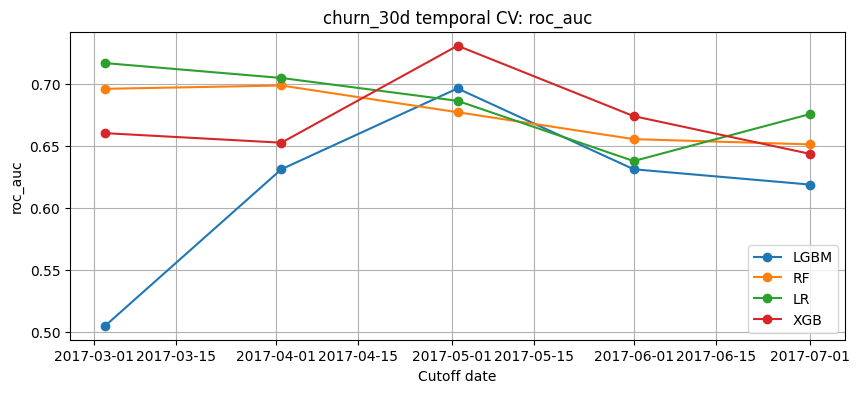

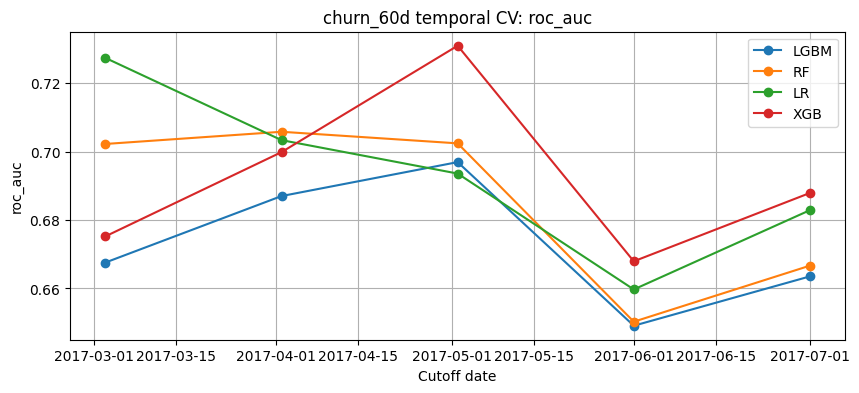

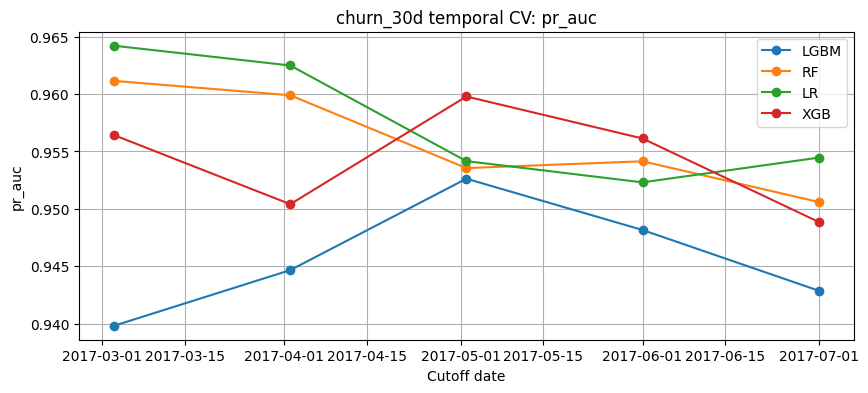

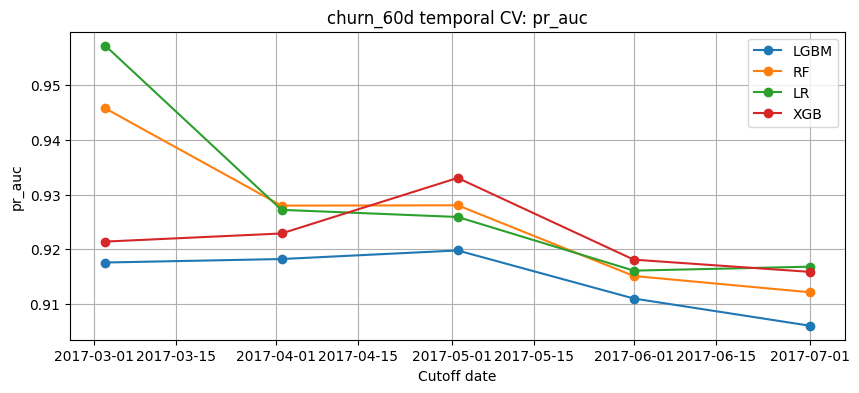

In [10]:
import matplotlib.pyplot as plt

def plot_metric(cv_df, target, metric="roc_auc"):
    d = cv_df[cv_df["target"] == target].copy()
    d["cutoff"] = pd.to_datetime(d["cutoff"])
    plt.figure(figsize=(10,4))
    for model in d["model"].unique():
        dd = d[d["model"] == model].sort_values("cutoff")
        plt.plot(dd["cutoff"], dd[metric], marker="o", label=model)
    plt.title(f"{target} temporal CV: {metric}")
    plt.xlabel("Cutoff date")
    plt.ylabel(metric)
    plt.legend()
    plt.grid(True)
    plt.show()

plot_metric(cv_df, "churn_30d", "roc_auc")
plot_metric(cv_df, "churn_60d", "roc_auc")
plot_metric(cv_df, "churn_30d", "pr_auc")
plot_metric(cv_df, "churn_60d", "pr_auc")